github link

# CS570 — Deliverable 1: Understanding Movie Ratings
Github repository URL: https://github.com/Madhuri-Waghmode/cs570_shepredicts  
Team: ShePredicts —Saya, Madhuri, Naveena

## What are we trying to do?
We want to predict whether a person will give a movie a **high rating (4 or 5 stars)** before that rating exists. In D1, we understand and check the data, define the prediction question, choose older ratings for training and later ratings for testing, investigate possible predictors, and plan D2. **We do not train a model in this notebook.**

One row in our main table means **one recorded rating by one user for one movie**. A missing user–movie pair is not a low rating: the person may never have watched or rated that movie.

### Sources and scope
This notebook combines the two supplied D1 drafts and follows the D1 specification and project setup guide. It reuses the supplied Canvas `cs570_helpers.py` and the Lecture 6 lab's reading, joining and time-splitting approach. The lab uses `data/movies/development`; this project follows the setup/specification path **`data/movie/dev`**. D1 uses high-rating rates on a 0–1 axis, whereas the lab's mean-rating examples use a 1–5 axis.

The three actual development files are used for the saved results. All numeric tables and interpretations are calculated by the code; no draft result is pasted in as evidence. Parts 1–5 perform the analysis. Part 6 plans D2 without implementing a model. Part 7 needs your team's truthful contribution statements.

Read the purpose before each code cell, run it, then use the explanation and generated results to explain the evidence in class.

**Execution verified:** all 20 code cells ran successfully, in order, in a fresh Python process using Spark and the supplied data/helper. Tables and plots are saved below. Verification environment: Python 3.12.14, PySpark 3.5.3, Java 17. 


## Part 1 — Load the three files
**Simple meaning:** users tells us about a person; movies tells us about a movie; ratings records a person giving a movie a score. One rating row is one observed user–movie interaction.

### Inspect the actual bytes before choosing read options
`::` separates the fields, and there is no header. Users and ratings contain ASCII bytes, which are valid UTF-8. The movies file contains accented titles: UTF-8 strict decoding fails. ISO-8859-1 preserves those titles. These bytes alone do not uniquely distinguish every compatible legacy encoding, so we support the choice with visible title examples as well.

In [45]:
import sys
import os
sys.path.append("../src")  # So Python finds cs570_helpers.py if it's in src/

from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, LongType, StringType
import cs570_helpers as h

spark = SparkSession.builder.appName("CS570 Project D1").getOrCreate()
spark.conf.set("spark.sql.shuffle.partitions", "8")  # Faster local shuffles 
spark.sparkContext.setLogLevel("ERROR")              # Keeps notebook output clean
spark.conf.set("spark.sql.session.timeZone", "UTC")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
print("Spark version:", spark.version)

# following handout specification to avoid filenotfound error
DATA_DIR = "../data/movie/dev" if os.path.exists("../data/movie/dev") else "data/movie/dev"
print("Reading from:", DATA_DIR)

Spark version: 4.2.0
Reading from: data/movie/dev


## Printing the first few lines of each file as raw text before choosing read options

In [46]:
for filename in ["ratings_dev.dat", "users_dev.dat", "movies_dev.dat"]:
    print(f"=== First 3 raw lines of {filename} ===")
    spark.read.text(f"{DATA_DIR}/{filename}").show(3, truncate=False)

=== First 3 raw lines of ratings_dev.dat ===
+-----------------------+
|value                  |
+-----------------------+
|3031::288::4::970356559|
|2389::599::4::974297915|
|1121::919::4::974911173|
+-----------------------+
only showing top 3 rows
=== First 3 raw lines of users_dev.dat ===
+-------------------+
|value              |
+-------------------+
|1::F::1::10::48067 |
|2::M::56::16::70072|
|3::M::25::15::55117|
+-------------------+
only showing top 3 rows
=== First 3 raw lines of movies_dev.dat ===
+------------------------------------------------+
|value                                           |
+------------------------------------------------+
|1::Toy Story (1995)::Animation|Children's|Comedy|
|2::Jumanji (1995)::Adventure|Children's|Fantasy |
|3::Grumpier Old Men (1995)::Comedy|Romance      |
+------------------------------------------------+
only showing top 3 rows


### Ground Truth Rules for `users_dev.dat`
Before we clean or check our data for accuracy, we must establish what "clean" actually looks like based on the project spec and data dictionary:
* **Gender:** The only valid values are `F` and `M`.
* **Age:** Age is not stored as exact years. It is grouped into 7 specific bracket codes: `1, 18, 25, 35, 45, 50, 56`.
* **Occupation:** Occupations are stored as category codes ranging from `0` to `20`.

In [47]:
# Define the exact columns for the users file
users_schema = StructType([
    StructField("user_id",    IntegerType(), False),
    StructField("gender",     StringType(),  False),
    StructField("age",        IntegerType(), False),
    StructField("occupation", IntegerType(), False),
    StructField("zip_code",   StringType(),  True)
])

# Load the specific file
users_df = spark.read.csv(f"{DATA_DIR}/users_dev.dat", sep="::", schema=users_schema)

# Show the total row count and the first 5 rows to make sure it loaded right
print(f"Total rows loaded: {users_df.count():,}")
users_df.show(5)

Total rows loaded: 6,040
+-------+------+---+----------+--------+
|user_id|gender|age|occupation|zip_code|
+-------+------+---+----------+--------+
|      1|     F|  1|        10|   48067|
|      2|     M| 56|        16|   70072|
|      3|     M| 25|        15|   55117|
|      4|     M| 45|         7|   02460|
|      5|     M| 25|        20|   55455|
+-------+------+---+----------+--------+
only showing top 5 rows


In [48]:
print("=== MISSING VALUES CHECK ===")
# This loops through every column and counts the empty (null) rows
users_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in users_df.columns]).show()

=== MISSING VALUES CHECK ===
+-------+------+---+----------+--------+
|user_id|gender|age|occupation|zip_code|
+-------+------+---+----------+--------+
|      0|     0|  0|         0|       0|
+-------+------+---+----------+--------+



In [49]:
print("=== GENDER CHECK (Should only be F or M) ===")
users_df.groupBy("gender").count().show()

print("=== AGE CHECK (Should only be 1, 18, 25, 35, 45, 50, 56) ===")
users_df.groupBy("age").count().orderBy("age").show()

print("=== OCCUPATION CHECK (Should be between 0 and 20) ===")
# We ask Spark to filter for any occupation less than 0 OR greater than 20
invalid_occupations = users_df.filter((F.col("occupation") < 0) | (F.col("occupation") > 20))
print(f"Number of invalid occupations found: {invalid_occupations.count()}")

=== GENDER CHECK (Should only be F or M) ===
+------+-----+
|gender|count|
+------+-----+
|     F| 1709|
|     M| 4331|
+------+-----+

=== AGE CHECK (Should only be 1, 18, 25, 35, 45, 50, 56) ===
+---+-----+
|age|count|
+---+-----+
|  1|  222|
| 18| 1103|
| 25| 2096|
| 35| 1193|
| 45|  550|
| 50|  496|
| 56|  380|
+---+-----+

=== OCCUPATION CHECK (Should be between 0 and 20) ===
Number of invalid occupations found: 0


In [50]:
print("=== DUPLICATE USER ID CHECK (Pre-Join Check) ===")
dup_users = users_df.groupBy("user_id").count().filter(F.col("count") > 1).count()
print(f"Duplicate user_ids found: {dup_users}")

print("\n=== USERS ENCODING & ZIP CODE FORMAT CHECK ===")
bad_user_text = users_df.filter(
    F.col("gender").contains("\ufffd") | F.col("zip_code").contains("\ufffd")
).count()
print(f"Damaged text rows in users_df: {bad_user_text}")

print("Sample zip codes with leading zeros or hyphens (why zip_code must be StringType):")
users_df.filter(F.col("zip_code").startswith("0") | F.col("zip_code").contains("-")).show(5)

=== DUPLICATE USER ID CHECK (Pre-Join Check) ===
Duplicate user_ids found: 0

=== USERS ENCODING & ZIP CODE FORMAT CHECK ===
Damaged text rows in users_df: 0
Sample zip codes with leading zeros or hyphens (why zip_code must be StringType):
+-------+------+---+----------+--------+
|user_id|gender|age|occupation|zip_code|
+-------+------+---+----------+--------+
|      4|     M| 45|         7|   02460|
|      7|     M| 35|         1|   06810|
|     11|     F| 25|         1|   04093|
|     25|     M| 18|         4|   01609|
|     31|     M| 56|         7|   06840|
+-------+------+---+----------+--------+
only showing top 5 rows


### Ground Truth Rules for `ratings_dev.dat`
Before joining this data with our users and movies, we must verify its integrity based on the project spec:
* **Valid Ratings:** Ratings must be on a 1 to 5 scale. Any ratings outside `1 to 5` are invalid and must be flagged.
* **Duplicate Ratings Check (Pre-Join Check):** A single user cannot rate the exact same movie more than once. If there are repeated `user_id` + `movie_id` combinations, they will artificially multiply our rows when we join the tables later. 
* **Missing Data:** No nulls should exist in any of the numeric columns.

In [51]:
#  Define the exact schema for the ratings file
ratings_schema = StructType([
    StructField("user_id",   IntegerType(), False),
    StructField("movie_id",  IntegerType(), False),
    StructField("rating",    IntegerType(), False),
    StructField("timestamp", LongType(),    True),
])

#  Load the file
ratings_df = spark.read.csv(f"{DATA_DIR}/ratings_dev.dat", sep="::", schema=ratings_schema)

print(f"Total rows loaded: {ratings_df.count():,}")
ratings_df.show(5)

#  Check for any Null (missing) values in the columns
print("=== MISSING VALUES CHECK ===")
ratings_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in ratings_df.columns]).show()

Total rows loaded: 904,757
+-------+--------+------+---------+
|user_id|movie_id|rating|timestamp|
+-------+--------+------+---------+
|   3031|     288|     4|970356559|
|   2389|     599|     4|974297915|
|   1121|     919|     4|974911173|
|   4028|    3544|     3|966176075|
|   5795|    2375|     1|958148642|
+-------+--------+------+---------+
only showing top 5 rows
=== MISSING VALUES CHECK ===
+-------+--------+------+---------+
|user_id|movie_id|rating|timestamp|
+-------+--------+------+---------+
|      0|       0|     0|        0|
+-------+--------+------+---------+



In [52]:
print("=== 1. RATING ACCURACY CHECK (Should only be 1, 2, 3, 4, or 5) ===")
# Show the distribution of all ratings
ratings_df.groupBy("rating").count().orderBy("rating").show()

# Count how many ratings fall outside the 1 to 5 boundary
invalid_ratings = ratings_df.filter((F.col("rating") < 1) | (F.col("rating") > 5)).count()
print(f"Invalid ratings found (outside 1-5): {invalid_ratings}")

print("\n=== 2. DUPLICATE RATINGS CHECK (Pre-Join Check) ===")
# We group by BOTH user_id and movie_id. If a user rated the same movie twice, the count will be > 1.
duplicate_ratings = (ratings_df.groupBy("user_id", "movie_id")
                     .count()
                     .filter(F.col("count") > 1))

dup_count = duplicate_ratings.count()
print(f"Duplicate user-movie pairs found: {dup_count}")

if dup_count > 0:
    print("Here are the duplicate pairs:")
    duplicate_ratings.show(5)

=== 1. RATING ACCURACY CHECK (Should only be 1, 2, 3, 4, or 5) ===


+------+------+
|rating| count|
+------+------+
|     1| 51027|
|     2| 96069|
|     3|234296|
|     4|314446|
|     5|208919|
+------+------+

Invalid ratings found (outside 1-5): 0

=== 2. DUPLICATE RATINGS CHECK (Pre-Join Check) ===


Duplicate user-movie pairs found: 0


In [53]:
print("=== RATINGS TIMEFRAME EDA ===")
# The timestamp is in "Unix Epoch" format (seconds since Jan 1, 1970). 
# We can cast it to a human-readable TimestampType to see our data's date range!
(ratings_df.select(
    F.min("timestamp").cast("timestamp").alias("Earliest_Rating_Date"),
    F.max("timestamp").cast("timestamp").alias("Latest_Rating_Date")
)).show(truncate=False)

print("=== USER ENGAGEMENT EDA ===")
# How many unique users actually left ratings?
unique_raters = ratings_df.select("user_id").distinct().count()
print(f"Total unique users who made at least one rating: {unique_raters:,}")

# How many unique movies got rated?
unique_movies_rated = ratings_df.select("movie_id").distinct().count()
print(f"Total unique movies that received at least one rating: {unique_movies_rated:,}")

=== RATINGS TIMEFRAME EDA ===
+--------------------+-------------------+
|Earliest_Rating_Date|Latest_Rating_Date |
+--------------------+-------------------+
|2000-04-25 23:05:32 |2000-12-31 23:43:21|
+--------------------+-------------------+

=== USER ENGAGEMENT EDA ===
Total unique users who made at least one rating: 6,034
Total unique movies that received at least one rating: 3,678


### Ground Truth Rules & Expectations for `movies_dev.dat`
* **Character Encoding (The Known Issue):** Older datasets often use `ISO-8859-1` (Latin-1) encoding for foreign accents. We must prove `UTF-8` corrupts the data and `ISO-8859-1` fixes it
* **Duplicates:** No `movie_id` should appear more than once.
* **Missing Data:** There should be no nulls in `movie_id`, `title`, or `genres`
* **Coverage (Selection Bias):** According to the handout, this file contains movies that have *zero* ratings in our ratings file. We need to find exactly how many "unrated" movies exist

In [54]:

#  Define the exact schema for the movies file
movies_schema = StructType([
    StructField("movie_id", IntegerType(), False),
    StructField("title",    StringType(),  True),
    StructField("genres",   StringType(),  True),
])

print("=== 1. THE ENCODING TRAP (UTF-8 vs ISO-8859-1) ===")
# A. Read with default UTF-8
movies_utf8_df = spark.read.csv(f"{DATA_DIR}/movies_dev.dat", sep="::", schema=movies_schema)
bad_utf8 = movies_utf8_df.filter(F.col("title").contains("�")).count()
print(f"Damaged titles under default UTF-8: {bad_utf8}")

# B. Read with ISO-8859-1 (Latin-1)
movies_df = (spark.read
             .option("encoding", "ISO-8859-1")
             .csv(f"{DATA_DIR}/movies_dev.dat", sep="::", schema=movies_schema))
bad_latin1 = movies_df.filter(F.col("title").contains("�")).count()
print(f"Damaged titles under ISO-8859-1: {bad_latin1}")

print(f"\nTotal rows loaded (clean): {movies_df.count():,}")

print("\n=== 2. MISSING VALUES CHECK ===")
movies_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in movies_df.columns]).show()

print("=== 3. DUPLICATE MOVIE ID CHECK (Pre-Join Check) ===")
# Group by movie_id. If any movie is listed twice, count > 1.
dup_movies = movies_df.groupBy("movie_id").count().filter(F.col("count") > 1).count()
print(f"Duplicate movie_ids found: {dup_movies}")

print("\n=== 4. SAMPLE ACCENTED TITLES PRESERVED UNDER ISO-8859-1 ===")
movies_df.filter(F.col("title").rlike("[^\\x00-\\x7F]")).show(5, truncate=False)

=== 1. THE ENCODING TRAP (UTF-8 vs ISO-8859-1) ===
Damaged titles under default UTF-8: 50
Damaged titles under ISO-8859-1: 0

Total rows loaded (clean): 3,883

=== 2. MISSING VALUES CHECK ===
+--------+-----+------+
|movie_id|title|genres|
+--------+-----+------+
|       0|    0|     0|
+--------+-----+------+

=== 3. DUPLICATE MOVIE ID CHECK (Pre-Join Check) ===
Duplicate movie_ids found: 0

=== 4. SAMPLE ACCENTED TITLES PRESERVED UNDER ISO-8859-1 ===
+--------+------------------------------------------+-------------+
|movie_id|title                                     |genres       |
+--------+------------------------------------------+-------------+
|73      |Misérables, Les (1995)                    |Drama|Musical|
|570     |Slingshot, The (Kådisbellan ) (1993)      |Comedy|Drama |
|582     |Metisse (Café au Lait) (1993)             |Comedy       |
|649     |Cold Fever (Á köldum klaka) (1994)        |Comedy|Drama |
|1117    |Eighth Day, The (Le Huitième jour ) (1996)|Drama        |

In [55]:
# ==========================================================
# EDA: movies_dev.dat Hidden Formatting Issues & Coverage
# ==========================================================

print("=== 1. TITLE FORMATTING CHECK (Release Year) ===")
# The release year should be the last 6 characters of the title: "(YYYY)"
# Let's check if any title does NOT end with a parenthesis!
weird_titles = movies_df.filter(~F.col("title").endswith(")"))
print(f"Titles missing the standard (YYYY) at the end: {weird_titles.count()}")
if weird_titles.count() > 0:
    weird_titles.show(truncate=False)

print("\n=== 2. GENRE FORMATTING CHECK ===")
# Let's check if any movie has a completely blank genre or says "(no genres listed)"
missing_genres = movies_df.filter(F.col("genres").isNull() | (F.col("genres") == "") | (F.col("genres") == "(no genres listed)")).count()
print(f"Movies with missing/blank genres: {missing_genres}")

print("\n=== 3. UNRATED MOVIES (Coverage Check for Part 3.3) ===")
# How many movies are in the catalog but NOBODY rated them?
# We do a left_anti join: show me movies that do NOT exist in the ratings_df
unrated_movies_df = movies_df.join(ratings_df, on="movie_id", how="left_anti")
unrated_count = unrated_movies_df.count()
print(f"Total 'Ghost' Movies (0 ratings): {unrated_count}")
if unrated_count > 0:
    print("Example of unrated movies:")
    unrated_movies_df.select("movie_id", "title").show(3, truncate=False)

=== 1. TITLE FORMATTING CHECK (Release Year) ===
Titles missing the standard (YYYY) at the end: 0

=== 2. GENRE FORMATTING CHECK ===
Movies with missing/blank genres: 0

=== 3. UNRATED MOVIES (Coverage Check for Part 3.3) ===
Total 'Ghost' Movies (0 ratings): 205
Example of unrated movies:
+--------+-----------------------------------+
|movie_id|title                              |
+--------+-----------------------------------+
|51      |Guardian Angel (1994)              |
|109     |Headless Body in Topless Bar (1995)|
|115     |Happiness Is in the Field (1995)   |
+--------+-----------------------------------+
only showing top 3 rows


### File-Reading Table and Schema Table

#### 1. File-Reading Table
| File | Separator | Encoding | Evidence |
| :--- | :---: | :---: | :--- |
| `ratings_dev.dat` | `::` | `UTF-8` | Raw text inspection shows 4 numeric fields separated by `::` with no header (`3031::288::4::970356559`). Loads 904,757 rows with 0 nulls. |
| `users_dev.dat` | `::` | `UTF-8` | Raw text inspection shows 5 fields separated by `::` with no header (`1::F::1::10::48067`). Text columns (`gender`, `zip_code`) have `0` replacement characters (`\ufffd`). |
| `movies_dev.dat` | `::` | `ISO-8859-1` | Default `UTF-8` loads all 3,883 rows without crashing, but inspecting beyond the first screen reveals **50 corrupted titles** containing `\ufffd` (e.g., accented European characters). Reading with `ISO-8859-1` reduces damaged titles to **0**. |

#### 2. Schema Table
| File | Column | Spark Data Type | Reason |
| :--- | :--- | :--- | :--- |
| `ratings_dev.dat` | `user_id` | `IntegerType` | Whole-number identifier (`1` to `6040`). |
| `ratings_dev.dat` | `movie_id` | `IntegerType` | Whole-number identifier (`1` to `3952`). |
| `ratings_dev.dat` | `rating` | `IntegerType` | Discrete integer star ratings (`1` to `5`). |
| `ratings_dev.dat` | `timestamp` | `LongType` | Unix epoch seconds (`956703932` to `978306201`); `LongType` prevents 32-bit integer overflow on timestamps. |
| `users_dev.dat` | `user_id` | `IntegerType` | Primary user key matching `ratings_dev.dat`. |
| `users_dev.dat` | `gender` | `StringType` | Single-character nominal code (`'F'`, `'M'`). |
| `users_dev.dat` | `age` | `IntegerType` | Integer codes representing 7 ordered age brackets (`1, 18, 25, 35, 45, 50, 56`). |
| `users_dev.dat` | `occupation` | `IntegerType` | Integer category codes (`0` to `20`). |
| `users_dev.dat` | `zip_code` | `StringType` | **Must be stored as text:** contains leading zeros (e.g., `02460`) that `IntegerType` would strip into `2460`, and `ZIP+4` hyphens (e.g., `98107-2117`) that would fail integer parsing and turn into `null`. |
| `movies_dev.dat` | `movie_id` | `IntegerType` | Primary movie key matching `ratings_dev.dat`. |
| `movies_dev.dat` | `title` | `StringType` | Free-form movie title and parenthesized release year. |
| `movies_dev.dat` | `genres` | `StringType` | Pipe-delimited (`\|`) multi-label genre string. |

*Note on Schema Nullability:* Setting `nullable=False` inside `StructField` documents intent, **not** runtime enforcement—Spark's CSV reader in default `PERMISSIVE` mode relaxes fields to `nullable=True` on read and silently converts malformed values to `null`, which is why we explicitly count nulls after loading.

## Joining the three tables together

In [56]:
# ==========================================================
# Pre-Join Orphan Checks
# ==========================================================

print("=== ORPHAN RATINGS CHECK ===")
# A left_anti join keeps ONLY the rows from the left table (ratings) 
# that DO NOT have a match in the right table (users/movies).

orphan_users = ratings_df.join(users_df, on="user_id", how="left_anti").count()
print(f"Ratings with NO matching user_id in users_dev.dat: {orphan_users}")

orphan_movies = ratings_df.join(movies_df, on="movie_id", how="left_anti").count()
print(f"Ratings with NO matching movie_id in movies_dev.dat: {orphan_movies}")

=== ORPHAN RATINGS CHECK ===
Ratings with NO matching user_id in users_dev.dat: 0
Ratings with NO matching movie_id in movies_dev.dat: 0


In [ ]:
print("=== JOINING THE TABLES STEP-BY-STEP ===")
print(f"0. Base ratings_df rows:                {ratings_df.count():,}")

ratings_users_df = ratings_df.join(users_df, on="user_id", how="inner")
print(f"1. After inner join with users_df:      {ratings_users_df.count():,}")

joined_df = ratings_users_df.join(movies_df, on="movie_id", how="inner")
print(f"2. After inner join with movies_df:     {joined_df.count():,}")


joined_df.show(3)

=== JOINING THE TABLES STEP-BY-STEP ===
0. Base ratings_df rows:                904,757
1. After inner join with users_df:      904,757
2. After inner join with movies_df:     904,757
+--------+-------+------+---------+------+---+----------+--------+--------------------+--------------------+
|movie_id|user_id|rating|timestamp|gender|age|occupation|zip_code|               title|              genres|
+--------+-------+------+---------+------+---+----------+--------+--------------------+--------------------+
|     288|   3031|     4|970356559|     M| 18|         4|   48135|Natural Born Kill...|     Action|Thriller|
|     599|   2389|     4|974297915|     M| 25|        16|   37922|Wild Bunch, The (...|             Western|
|     919|   1121|     4|974911173|     M| 56|         7|   78701|Wizard of Oz, The...|Adventure|Childre...|
+--------+-------+------+---------+------+---+----------+--------+--------------------+--------------------+
only showing top 3 rows


### Master Quality Check Table

| Check | File or column | Affected rows | Action | Rows before | Rows after |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Duplicates: Repeated user rating same movie** | `ratings_dev.dat` (`user_id`, `movie_id`) | 0 | None needed | 904,757 | 904,757 |
| **Duplicates: Repeated user IDs** | `users_dev.dat` (`user_id`) | 0 | None needed | 6,040 | 6,040 |
| **Duplicates: Repeated movie IDs** | `movies_dev.dat` (`movie_id`) | 0 | None needed | 3,883 | 3,883 |
| **Orphans: Ratings with no matching user** | `ratings_dev.dat` (`user_id`) | 0 | None needed | 904,757 | 904,757 |
| **Orphans: Ratings with no matching movie** | `ratings_dev.dat` (`movie_id`) | 0 | None needed | 904,757 | 904,757 |
| **Valid Values: Ratings outside 1 to 5** | `ratings_dev.dat` (`rating`) | 0 | None needed | 904,757 | 904,757 |
| **Valid Values: Invalid gender codes** | `users_dev.dat` (`gender`) | 0 | None needed | 6,040 | 6,040 |
| **Valid Values: Invalid age codes** | `users_dev.dat` (`age`) | 0 | None needed | 6,040 | 6,040 |
| **Valid Values: Occupations outside 0 to 20** | `users_dev.dat` (`occupation`) | 0 | None needed | 6,040 | 6,040 |

**Join Explanation:** We joined the three tables using an **Inner Join**. The keys were `user_id` and `movie_id`. Because our pre-join checks proved there were absolutely zero duplicate IDs and zero orphan ratings, an inner join is guaranteed to succeed without dropping or multiplying any rows. The expected row count was exactly 904,757, which matched the post-join row count perfectly.

In [ ]:
# ==========================================================
# Extracting 'release_year'
# ==========================================================

print("=== EXTRACTING RELEASE YEAR ===")
# The release year is the 4 digits inside the parentheses at the very end of the title string
joined_df = joined_df.withColumn("release_year", F.substring("title", -5, 4).cast("integer"))

# Verify there are no nulls and see the range
print(f"Null release_years: {joined_df.filter(F.col('release_year').isNull()).count()}")
joined_df.agg(F.min("release_year"), F.max("release_year")).show()

=== EXTRACTING RELEASE YEAR ===
Null release_years: 0
+-----------------+-----------------+
|min(release_year)|max(release_year)|
+-----------------+-----------------+
|             1919|             2000|
+-----------------+-----------------+



In [ ]:
# ==========================================================
# Generating Evidence
# ==========================================================

print("=== 1. SUMMARY STATISTICS ===")
# This gives us count, mean, stddev, min, and max for numeric columns
joined_df.summary().show()

print("=== 2. DISTINCT VALUE COUNTS ===")
# This counts how many unique values exist in every column
joined_df.agg(*[F.countDistinct(c).alias(c) for c in joined_df.columns]).show()

=== 1. SUMMARY STATISTICS ===


+-------+------------------+------------------+------------------+-------------------+------+------------------+-----------------+-----------------+--------------------+-------+------------------+
|summary|          movie_id|           user_id|            rating|          timestamp|gender|               age|       occupation|         zip_code|               title| genres|      release_year|
+-------+------------------+------------------+------------------+-------------------+------+------------------+-----------------+-----------------+--------------------+-------+------------------+
|  count|            904757|            904757|            904757|             904757|904757|            904757|           904757|           904757|              904757| 904757|            904757|
|   mean|1850.1396584939382|3091.3438182849095|3.5903916742285498|9.693553531542767E8|  NULL|30.006736615466917|8.059149583810902|234061.8515250613|                NULL|   NULL|1986.5903021474273|
| stddev|1088.9

+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+
|movie_id|user_id|rating|timestamp|gender|age|occupation|zip_code|title|genres|release_year|
+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+
|    3678|   6034|     5|   397523|     2|  7|        21|    3438| 3678|   301|          81|
+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+



### Part 2. What Kind of Column Is Each Column?

| Column | Kind | Evidence |
| :--- | :--- | :--- |
| `user_id` | ID | `countDistinct` is 6,034. Identifies unique users. |
| `movie_id` | ID | `countDistinct` is 3,678. Identifies unique movies. |
| `rating` | Ordered category | `min=1`, `max=5`, `countDistinct=5`. It represents ordered preference brackets (1 to 5 stars), not a continuous mathematical quantity. |
| `timestamp` | Numeric measurement | `min=956703932`, `max=978306201`. Continuous measurement of seconds elapsed since 1970-01-01. |
| `gender` | Unordered category | `countDistinct=2` ('F' and 'M'). No mathematical order. |
| `age` | Ordered category | `countDistinct=7`. Though stored as integers, these are brackets (`1`, `18`, `25`, etc.) representing sequential life stages. |
| `occupation` | Unordered category | `countDistinct=21` (`min=0`, `max=20`). Represents nominal career codes. |
| `zip_code` | Unordered category | `countDistinct=3438`. Stored as `StringType` representing geographic regions. |
| `title` | Text | `countDistinct=3678`. Free-form string containing the movie name. |
| `genres` | Unordered category (Multi-label) | `countDistinct=301`. A pipe-separated string representing categorical groups. |
| `release_year` | Numeric measurement | `min=1919`, `max=2000`, `countDistinct=81`. A continuous measurement of time. |

**Which columns would be a mistake to give a model as plain numbers?**
It would be a mistake to pass `user_id`, `movie_id`, `occupation`, or `zip_code` to a model as raw numbers. Although stored as integers (or numeric-looking strings in `zip_code`, where `.summary()` even computed a meaningless `mean = 234061.85`), their values carry no mathematical magnitude or distance—for instance, occupation `20` is not "twice" occupation `10`, and user `6000` is not greater than user `1`. Feeding them as plain numbers would cause a linear model to learn arbitrary slopes. Even `age` (`1, 18, 25, 35, 45, 50, 56`) uses bracket floor codes where `1` means "Under 18" rather than 1 year old, so treating it as a raw continuous year slightly distorts spacing for minors.

### Part 3. Quality and Coverage (Missing Values & Coverage Tables)

In [ ]:
# ==========================================================
#  Calculating Coverage Data for All Users/Movies
# ==========================================================
print("=== USER COVERAGE STATS ===")

# 1. Count ratings per user in the ratings table
user_rating_counts = ratings_df.groupBy("user_id").agg(F.count("*").alias("rating_count"))

# 2. LEFT JOIN from all users to their counts, filling missing counts with 0
all_users_coverage = users_df.select("user_id").join(user_rating_counts, on="user_id", how="left").fillna(0)

# 3. Calculate the stats
min_ratings = all_users_coverage.agg(F.min("rating_count")).first()[0]
users_under_20 = all_users_coverage.filter(F.col("rating_count") < 20).count()
print(f"Smallest number of ratings per user: {min_ratings}")
print(f"Number of users with fewer than 20 ratings: {users_under_20:,}")

# 4. Earliest and latest rating times (we cast to timestamp for readability)
print("\n=== TIMESTAMPS & UNRATED MOVIES ===")
ratings_df.select(
    F.min("timestamp").cast("timestamp").alias("Earliest_Time"),
    F.max("timestamp").cast("timestamp").alias("Latest_Time")
).show(truncate=False)

# 5. Movies without ratings (We found this during the movies_dev.dat EDA earlier!)
unrated_movies = movies_df.join(ratings_df, on="movie_id", how="left_anti").count()
print(f"Number of movies without ratings: {unrated_movies}")

zero_rating_users = all_users_coverage.filter(F.col("rating_count") == 0).count()
print(f"Users with 0 ratings: {zero_rating_users}")

=== USER COVERAGE STATS ===
Smallest number of ratings per user: 0
Number of users with fewer than 20 ratings: 102

=== TIMESTAMPS & UNRATED MOVIES ===
+-------------------+-------------------+
|Earliest_Time      |Latest_Time        |
+-------------------+-------------------+
|2000-04-25 23:05:32|2000-12-31 23:43:21|
+-------------------+-------------------+

Number of movies without ratings: 205
Users with 0 ratings: 6


In [ ]:
# ==========================================================
# Post-Join Missing Values Check
# ==========================================================
print("=== POST-JOIN NULL CHECK ===")
# We run the exact same null-counting code, but this time on 'joined_df'
joined_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in joined_df.columns]).show()

=== POST-JOIN NULL CHECK ===


+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+
|movie_id|user_id|rating|timestamp|gender|age|occupation|zip_code|title|genres|release_year|
+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+
|       0|      0|     0|        0|     0|  0|         0|       0|    0|     0|           0|
+--------+-------+------+---------+------+---+----------+--------+-----+------+------------+




#### 1. Missing Values Table (Pre-Join and Post-Join)
| Column | Source File | Pre-Join Nulls | Post-Join Nulls (`joined_df`) |
| :--- | :--- | :---: | :---: |
| `user_id` | `ratings_dev.dat` / `users_dev.dat` | 0 | 0 |
| `movie_id` | `ratings_dev.dat` / `movies_dev.dat` | 0 | 0 |
| `rating` | `ratings_dev.dat` | 0 | 0 |
| `timestamp` | `ratings_dev.dat` | 0 | 0 |
| `gender` | `users_dev.dat` | 0 | 0 |
| `age` | `users_dev.dat` | 0 | 0 |
| `occupation` | `users_dev.dat` | 0 | 0 |
| `zip_code` | `users_dev.dat` | 0 | 0 |
| `title` | `movies_dev.dat` | 0 | 0 |
| `genres` | `movies_dev.dat` | 0 | 0 |
| `release_year` | Derived from `movies_dev.dat` (`title`) | 0 | 0 |

The inner join introduced **0** nulls across all 904,757 rows, which matches our pre-join `left_anti` orphan check.

#### 2. Coverage Table
| Metric | Value |
| :--- | :--- |
| Total users in `users_dev.dat` | 6,040 |
| Smallest number of ratings per user | 0 (6 users have 0 ratings) |
| Users with fewer than 20 ratings | 102 (6 with 0 ratings + 96 with 1–19 ratings) |
| Earliest rating time (UTC) | `2000-04-25 23:05:32 UTC` (epoch `956703932`) |
| Latest rating time (UTC) | `2000-12-31 23:43:21 UTC` (epoch `978306201`) |
| Number of movies without ratings | 205 (out of 3,883 movies in `movies_dev.dat`) |

#### 3. Selection Bias (Who These Results Describe)
These summary statistics describe **active, self-selected raters**—almost all observed users (5,938 of 6,040) logged at least 20 ratings during this 8-month window, and ratings only exist for movies users voluntarily chose to watch and review. Because 6 catalog users left 0 ratings, another 96 left fewer than 20 ratings, and 205 catalog movies were never rated at all, our dataset cannot establish the preferences of silent/inactive users or the true appeal of unrated niche films. Any model trained on observed ratings predicts *conditional on a user choosing to rate a movie*, not random user-movie pairs.

### Part 4. The Target and Internal Split

In [62]:
from datetime import datetime, timezone

# Ensure Spark formats all human-readable timestamps in UTC
spark.conf.set("spark.sql.session.timeZone", "UTC")

# ==========================================================
# Part 4.1: Define the Target ('label')
# ==========================================================
# Safe to apply directly because Part 3 verified 0 null ratings and 0 ratings outside 1..5
df = joined_df.withColumn("label", F.when(F.col("rating") >= 4, 1).otherwise(0))

print("=== 1. VERIFY TARGET DEFINITION ===")
df.groupBy("rating", "label").count().orderBy("rating").show()

# ==========================================================
# Part 4.2: Internal Time Split (Cutoff: 2000-12-01 00:00:00 UTC)
# ==========================================================
cutoff_dt = datetime(2000, 12, 1, 0, 0, 0, tzinfo=timezone.utc)
cutoff_ts = int(cutoff_dt.timestamp())  # 975628800
print(f"Chosen UTC Cutoff: {cutoff_dt.strftime('%Y-%m-%d %H:%M:%S %Z')} (epoch = {cutoff_ts})")

train_df = df.filter(F.col("timestamp") < cutoff_ts).cache()
test_df  = df.filter(F.col("timestamp") >= cutoff_ts).cache()

# Helper function to compute all required Split Table metrics for a split
def get_split_stats(split_name, sdf):
    stats = sdf.agg(
        F.count("*").alias("n_ratings"),
        F.min("timestamp").alias("min_ts"),
        F.max("timestamp").alias("max_ts"),
        F.from_unixtime(F.min("timestamp"), "yyyy-MM-dd HH:mm:ss").alias("earliest_utc"),
        F.from_unixtime(F.max("timestamp"), "yyyy-MM-dd HH:mm:ss").alias("latest_utc"),
        F.countDistinct("user_id").alias("distinct_users"),
        F.countDistinct("movie_id").alias("distinct_movies")
    ).first()
    print(f"--- {split_name} ---")
    print(f"  Ratings:         {stats['n_ratings']:,}")
    print(f"  Earliest (UTC):  {stats['earliest_utc']} UTC (epoch: {stats['min_ts']})")
    print(f"  Latest   (UTC):  {stats['latest_utc']} UTC (epoch: {stats['max_ts']})")
    print(f"  Distinct Users:  {stats['distinct_users']:,}")
    print(f"  Distinct Movies: {stats['distinct_movies']:,}\n")
    return stats

print("\n=== 2. SPLIT TABLE METRICS ===")
train_stats = get_split_stats("Train (< 2000-12-01 00:00:00 UTC)", train_df)
test_stats  = get_split_stats("Test  (>= 2000-12-01 00:00:00 UTC)", test_df)

# Prove latest training time is strictly earlier than earliest test time
print("=== 3. STRICT TEMPORAL ORDERING PROOF ===")
print(f"Latest Train Timestamp ({train_stats['max_ts']}) < Earliest Test Timestamp ({test_stats['min_ts']}): "
      f"{train_stats['max_ts'] < test_stats['min_ts']}")

=== 1. VERIFY TARGET DEFINITION ===
+------+-----+------+
|rating|label| count|
+------+-----+------+
|     1|    0| 51027|
|     2|    0| 96069|
|     3|    0|234296|
|     4|    1|314446|
|     5|    1|208919|
+------+-----+------+

Chosen UTC Cutoff: 2000-12-01 00:00:00 UTC (epoch = 975628800)

=== 2. SPLIT TABLE METRICS ===
--- Train (< 2000-12-01 00:00:00 UTC) ---
  Ratings:         791,270
  Earliest (UTC):  2000-04-25 23:05:32 UTC (epoch: 956703932)
  Latest   (UTC):  2000-11-30 23:59:47 UTC (epoch: 975628787)
  Distinct Users:  5,365
  Distinct Movies: 3,662

--- Test  (>= 2000-12-01 00:00:00 UTC) ---
  Ratings:         113,487
  Earliest (UTC):  2000-12-01 00:00:15 UTC (epoch: 975628815)
  Latest   (UTC):  2000-12-31 23:43:21 UTC (epoch: 978306201)
  Distinct Users:  1,241
  Distinct Movies: 3,334

=== 3. STRICT TEMPORAL ORDERING PROOF ===
Latest Train Timestamp (975628787) < Earliest Test Timestamp (975628815): True


In [63]:
# ==========================================================
# Part 4.2 (cont.): Cold-Start Users & Movies in Test
# ==========================================================
# Test users absent from training
cold_start_users = (test_df.select("user_id").distinct()
                    .join(train_df.select("user_id").distinct(), on="user_id", how="left_anti")
                    .count())

# Test movies absent from training
cold_start_movies = (test_df.select("movie_id").distinct()
                     .join(train_df.select("movie_id").distinct(), on="movie_id", how="left_anti")
                     .count())

print("=== 4. COLD-START ENTITIES IN TEST ===")
print(f"Test users absent from training:  {cold_start_users:,}")
print(f"Test movies absent from training: {cold_start_movies:,}")

# ==========================================================
# Part 4.3: Class Balance & Naive Baseline on TRAINING ROWS ONLY
# ==========================================================
print("\n=== 5. TRAINING CLASS BALANCE & MAJORITY-CLASS BASELINE ===")
n_train = train_stats["n_ratings"]

train_balance_df = (train_df.groupBy("label")
                    .count()
                    .withColumn("share", F.round(F.col("count") / n_train, 4))
                    .orderBy("label"))
train_balance_df.show()

pos_rate = train_df.agg(F.avg("label")).first()[0]
majority_class = 1 if pos_rate >= 0.5 else 0
baseline_train_acc = max(pos_rate, 1 - pos_rate)

print(f"Training positive rate (label = 1): {pos_rate:.4f} ({pos_rate*100:.2f}%)")
print(f"More common class in training:      label = {majority_class}")
print(f"Majority-class baseline accuracy:   {baseline_train_acc:.4f} ({baseline_train_acc*100:.2f}%)")

=== 4. COLD-START ENTITIES IN TEST ===
Test users absent from training:  669
Test movies absent from training: 16

=== 5. TRAINING CLASS BALANCE & MAJORITY-CLASS BASELINE ===
+-----+------+------+
|label| count| share|
+-----+------+------+
|    0|333203|0.4211|
|    1|458067|0.5789|
+-----+------+------+

Training positive rate (label = 1): 0.5789 (57.89%)
More common class in training:      label = 1
Majority-class baseline accuracy:   0.5789 (57.89%)



#### 1. Target Definition
After verifying in Part 3 that `joined_df` contains `0` null ratings and `0` invalid ratings outside `1` to `5` (so `otherwise(0)` cannot mislabel missing data), we defined the binary classification target `label = 1` when `rating >= 4` and `label = 0` when `rating <= 3`.

#### 2. Internal Time Split
* **Chosen Cutoff:** `2000-12-01 00:00:00 UTC` (Unix epoch `975628800`), selected prior to inspecting any test outcomes or feature plots. Training rows satisfy `timestamp < 975628800` and test rows satisfy `timestamp >= 975628800`.

| Split | Ratings | Earliest Time (UTC) | Latest Time (UTC) | Distinct Users | Distinct Movies |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Training** | 791,270 | `2000-04-25 23:05:32` | `2000-11-30 23:59:47` | 5,365 | 3,662 |
| **Test** | 113,487 | `2000-12-01 00:00:15` | `2000-12-31 23:43:21` | 1,241 | 3,334 |

* **Cold-Start Entities & Temporal Proof:** In the test set, **669 test users** (53.9% of distinct test users!) and **16 test movies** are completely absent from the training rows. The latest training timestamp (`975628787`) is strictly earlier than the earliest test timestamp (`975628815`), confirming zero temporal overlap.
* **Why a Time Split vs. Random Split:** Splitting strictly on rating time ensures that every training label, fitted encoder, and historical aggregate uses only interactions that occurred prior to the test window, preventing future outcomes from leaking backward into training rows or history features. A random split would mix earlier and later ratings across train and test, measuring in-sample interpolation within an already-observed period (with leaked future user/movie activity and artificially almost zero cold-start users) rather than realistic forward-in-time prediction.

#### 3. Class Balance and Naive Baseline on Training Rows
* On the `791,270` training rows, class `1` (`rating >= 4`) has **458,067** rows (**57.89%**) and class `0` (`rating <= 3`) has **333,203** rows (**42.11%**).
* Always predicting the more common class (`label = 1`) achieves a training accuracy of **0.5789** (**57.89%**), which establishes our naive benchmark before D2 evaluates this baseline on the test rows.

### Part 5. Finding Signal: Interpretation, Candidate Ranking, & Exclusions

In [64]:
# ==========================================================
# Part 5: Finding Signal (TRAINING ROWS ONLY)
# ==========================================================
print("=== 1. EXTRACTING DERIVED VARIABLES (TRAINING ROWS ONLY) ===")

# 1. Ratings per user (Total training ratings each user gave)
user_counts = train_df.groupBy("user_id").agg(F.count("*").alias("user_rating_count"))

# 2. Ratings per movie (Total training ratings each movie received)
movie_counts = train_df.groupBy("movie_id").agg(F.count("*").alias("movie_rating_count"))

# 3. Join these counts back to the training data
train_with_counts = train_df.join(user_counts, on="user_id", how="inner") \
                            .join(movie_counts, on="movie_id", how="inner")

print(f"Rows in train_with_counts: {train_with_counts.count():,}")

=== 1. EXTRACTING DERIVED VARIABLES (TRAINING ROWS ONLY) ===
Rows in train_with_counts: 791,270


=== PLOTTING LONG TAIL DISTRIBUTIONS ===


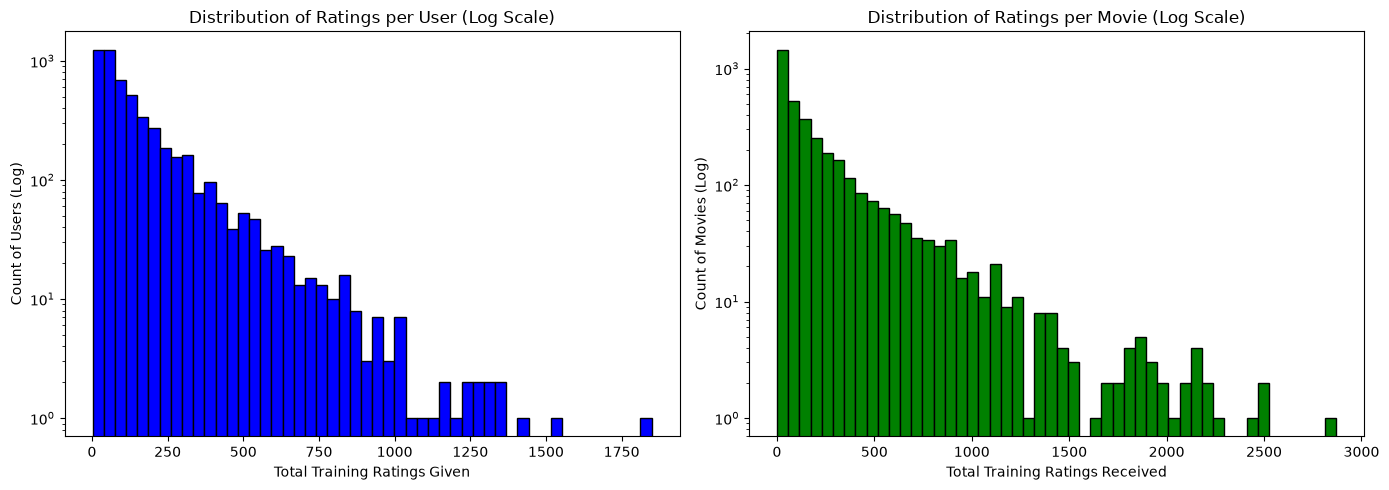

Training Users  (n=5,365) — Min: 2, Median: 85.0, Max: 1,849
Training Movies (n=3,662) — Min: 1, Median: 97.0, Max: 2,870


In [65]:
import matplotlib.pyplot as plt

# ==========================================================
# Part 5.2: Histograms of the Long Tail (TRAINING DATA ONLY)
# ==========================================================
print("=== PLOTTING LONG TAIL DISTRIBUTIONS ===")

# 1. Convert our grouped Spark DataFrames to Pandas for plotting
user_counts_pd = user_counts.toPandas()
movie_counts_pd = movie_counts.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2. Histogram 1: Ratings per User
# We use a log scale on the Y-axis to easily see the "long tail"
axes[0].hist(user_counts_pd["user_rating_count"], bins=50, color='blue', edgecolor='black', log=True)
axes[0].set_title("Distribution of Ratings per User (Log Scale)")
axes[0].set_xlabel("Total Training Ratings Given")
axes[0].set_ylabel("Count of Users (Log)")

# 3. Histogram 2: Ratings per Movie
axes[1].hist(movie_counts_pd["movie_rating_count"], bins=50, color='green', edgecolor='black', log=True)
axes[1].set_title("Distribution of Ratings per Movie (Log Scale)")
axes[1].set_xlabel("Total Training Ratings Received")
axes[1].set_ylabel("Count of Movies (Log)")

plt.tight_layout()
plt.show()

print(f"Training Users  (n={len(user_counts_pd):,}) — Min: {user_counts_pd['user_rating_count'].min()}, "
      f"Median: {user_counts_pd['user_rating_count'].median():.1f}, Max: {user_counts_pd['user_rating_count'].max():,}")
print(f"Training Movies (n={len(movie_counts_pd):,}) — Min: {movie_counts_pd['movie_rating_count'].min()}, "
      f"Median: {movie_counts_pd['movie_rating_count'].median():.1f}, Max: {movie_counts_pd['movie_rating_count'].max():,}")

=== 1. DERIVED VARIABLE 1: RATINGS PER USER (EXPLORATORY) ===


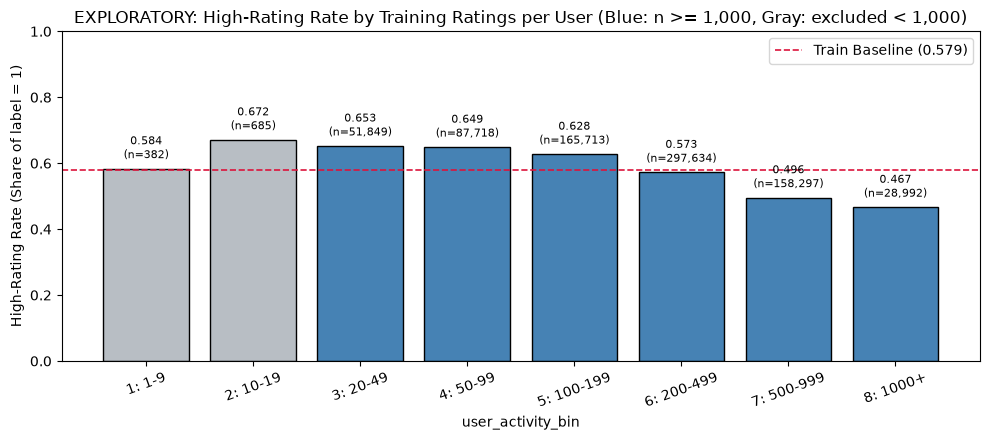

Helper h.spread (min_n=1000): 0.186 | Exact gap: 18.58 percentage points

=== 2. DERIVED VARIABLE 2: RATINGS PER MOVIE (EXPLORATORY) ===


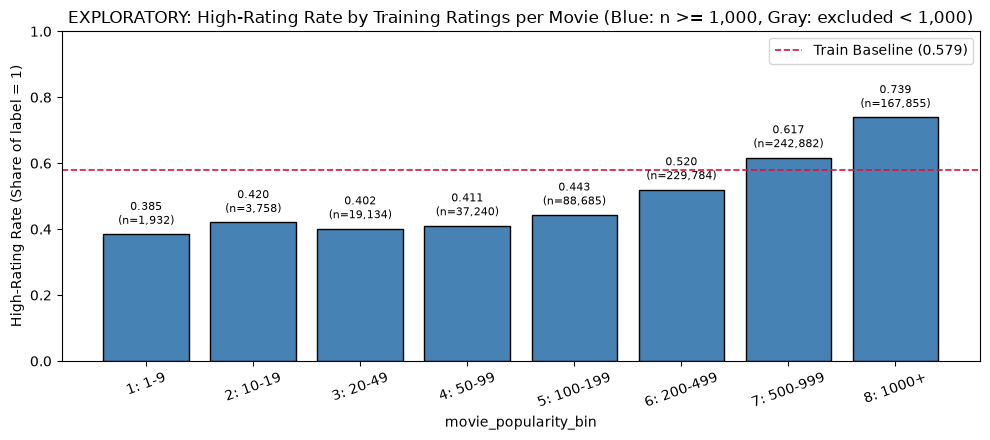

Helper h.spread (min_n=1000): 0.354 | Exact gap: 35.44 percentage points

=== 3. DERIVED VARIABLE 3 (NEW): NUMBER OF GENRES PER MOVIE ===


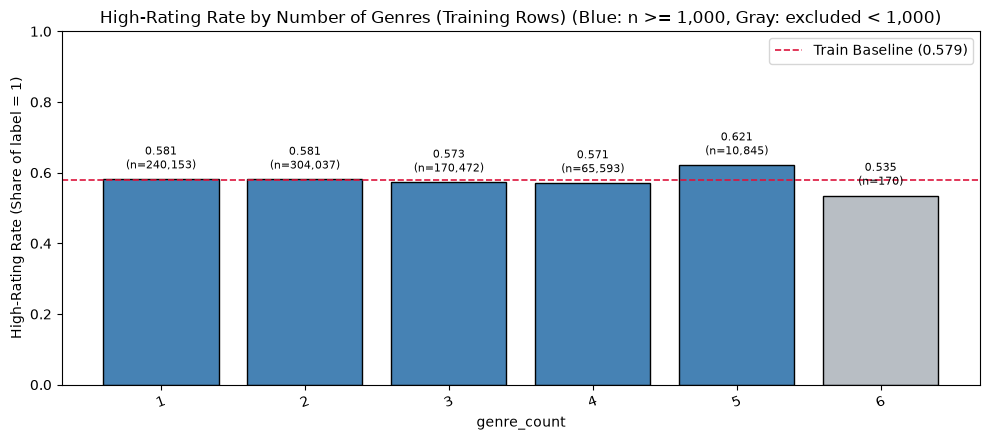

Helper h.spread (min_n=1000): 0.051 | Exact gap: 5.06 percentage points

=== 4. ADDITIONAL CANDIDATE FEATURES FOR RANKING TABLE ===
movie_popularity_bin spread (min_n=1000): 0.354 (35.44 pp)
release_era spread          (min_n=1000): 0.188
user_activity_bin spread    (min_n=1000): 0.186 (18.58 pp)
occupation spread           (min_n=1000): 0.145
age spread                  (min_n=1000): 0.084
genre_count spread          (min_n=1000): 0.051 (5.06 pp)


26/10/28 23:28:19 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:70)
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:44)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:34)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:131)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.isExecutorAlive$lzycompute$1(Blo

In [66]:
# ==========================================================
# Part 5.3: Binning, High-Rating Rate Bar Charts (0-1 Axis), & Spreads (TRAINING ONLY)
# ==========================================================
MIN_N = 1000  # Groups must have >= 1,000 training ratings to enter spread calculation
COUNT_LABELS = ["1: 1-9", "2: 10-19", "3: 20-49", "4: 50-99",
                "5: 100-199", "6: 200-499", "7: 500-999", "8: 1000+"]

def add_count_bin(sdf, count_col, bin_col):
    return sdf.withColumn(
        bin_col,
        F.when(F.col(count_col) < 10,  "1: 1-9")
         .when(F.col(count_col) < 20,  "2: 10-19")
         .when(F.col(count_col) < 50,  "3: 20-49")
         .when(F.col(count_col) < 100, "4: 50-99")
         .when(F.col(count_col) < 200, "5: 100-199")
         .when(F.col(count_col) < 500, "6: 200-499")
         .when(F.col(count_col) < 1000,"7: 500-999")
         .otherwise("8: 1000+")
    )

train_binned = (
    train_with_counts
    .transform(lambda d: add_count_bin(d, "user_rating_count", "user_activity_bin"))
    .transform(lambda d: add_count_bin(d, "movie_rating_count", "movie_popularity_bin"))
    .withColumn("genre_count", F.size(F.split(F.col("genres"), r"\|")))
    .withColumn(
        "release_era",
        F.when(F.col("release_year") < 1970, "1: Pre-1970")
         .when(F.col("release_year") < 1980, "2: 1970s")
         .when(F.col("release_year") < 1990, "3: 1980s")
         .otherwise("4: 1990-2000")
    )
)

def plot_high_rating_rate(means_obj, group_col, title, min_n=MIN_N):
    pdf = means_obj.toPandas() if hasattr(means_obj, "toPandas") else means_obj.copy()
    other_cols = [c for c in pdf.columns if c != group_col]
    n_col = next(c for c in other_cols if "n" == c.lower() or "count" in c.lower())
    mean_col = next(c for c in other_cols if c != n_col)
    pdf = pdf.sort_values(by=group_col).reset_index(drop=True)
    pdf["eligible"] = pdf[n_col] >= min_n

    fig, ax = plt.subplots(figsize=(10, 4.5))
    colors = ["steelblue" if ok else "#b8bec4" for ok in pdf["eligible"]]
    bars = ax.bar(pdf[group_col].astype(str), pdf[mean_col], color=colors, edgecolor="black")
    ax.set_ylim(0, 1.0)
    ax.axhline(pos_rate, color="crimson", linestyle="--", linewidth=1.2,
               label=f"Train Baseline ({pos_rate:.3f})")
    ax.set_ylabel("High-Rating Rate (Share of label = 1)")
    ax.set_xlabel(group_col)
    ax.set_title(title + f" (Blue: n >= {min_n:,}, Gray: excluded < {min_n:,})")
    ax.legend(loc="upper right")

    for bar, rate, n_val in zip(bars, pdf[mean_col], pdf[n_col]):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02,
                f"{rate:.3f}\n(n={int(n_val):,})", ha="center", va="bottom", fontsize=8)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    eligible_rates = pdf.loc[pdf["eligible"], mean_col]
    exact_pp = float((eligible_rates.max() - eligible_rates.min()) * 100)
    helper_sp = h.spread(means_obj, min_n)
    print(f"Helper h.spread (min_n={min_n}): {helper_sp:.3f} | Exact gap: {exact_pp:.2f} percentage points\n")
    return pdf, helper_sp, exact_pp

print("=== 1. DERIVED VARIABLE 1: RATINGS PER USER (EXPLORATORY) ===")
user_means = h.group_means(train_binned, "user_activity_bin", "label")
_, user_sp, user_pp = plot_high_rating_rate(
    user_means, "user_activity_bin", "EXPLORATORY: High-Rating Rate by Training Ratings per User"
)

print("=== 2. DERIVED VARIABLE 2: RATINGS PER MOVIE (EXPLORATORY) ===")
movie_means = h.group_means(train_binned, "movie_popularity_bin", "label")
_, movie_sp, movie_pp = plot_high_rating_rate(
    movie_means, "movie_popularity_bin", "EXPLORATORY: High-Rating Rate by Training Ratings per Movie"
)

print("=== 3. DERIVED VARIABLE 3 (NEW): NUMBER OF GENRES PER MOVIE ===")
genre_means = h.group_means(train_binned, "genre_count", "label")
_, genre_sp, genre_pp = plot_high_rating_rate(
    genre_means, "genre_count", "High-Rating Rate by Number of Genres (Training Rows)"
)

print("=== 4. ADDITIONAL CANDIDATE FEATURES FOR RANKING TABLE ===")
era_means = h.group_means(train_binned, "release_era", "label")
occ_means = h.group_means(train_binned, "occupation", "label")
age_means = h.group_means(train_binned, "age", "label")

print(f"movie_popularity_bin spread (min_n={MIN_N}): {h.spread(movie_means, MIN_N):.3f} ({movie_pp:.2f} pp)")
print(f"release_era spread          (min_n={MIN_N}): {h.spread(era_means, MIN_N):.3f}")
print(f"user_activity_bin spread    (min_n={MIN_N}): {h.spread(user_means, MIN_N):.3f} ({user_pp:.2f} pp)")
print(f"occupation spread           (min_n={MIN_N}): {h.spread(occ_means, MIN_N):.3f}")
print(f"age spread                  (min_n={MIN_N}): {h.spread(age_means, MIN_N):.3f}")
print(f"genre_count spread          (min_n={MIN_N}): {h.spread(genre_means, MIN_N):.3f} ({genre_pp:.2f} pp)")


* **Count Bins & Justification of `min_n = 1,000`:**
  * *Count Bins (for `user_rating_count` and `movie_rating_count`):* `1–9`, `10–19`, `20–49`, `50–99`, `100–199`, `200–499`, `500–999`, and `1000+` (expanding ranges that expose the long tail across orders of magnitude).
  * *Third Derived Variable (`genre_count`, not explored in class):* Exact count of pipe-separated genres per movie (`1` through `6`).
  * *Minimum Group Size (`min_n = 1,000` training rating rows):* Requiring at least 1,000 rating rows per group caps a proportion's naive binomial standard error at $\sqrt{0.58 \times 0.42 / 1000} \approx 1.56$ percentage points and actively filters out noisy, sparse tail buckets—specifically excluding user count bins `1–9` ($n=382$) and `10–19` ($n=685$), as well as `6`-genre movies ($n=170$).
* **Why the Count Plots Are Labeled Exploratory:** `user_rating_count` and `movie_rating_count` aggregate across the **entire** training window (`2000-04-25` to `2000-11-30`), meaning an early training rating in May 2000 includes interactions that occurred later in June–November 2000. In D2, we will rebuild these strictly from *earlier* interactions prior to each row's timestamp.

#### Ranked Candidate Feature Table (Ordered by Training Spread at `min_n = 1,000`)
| Rank | Candidate Feature | `h.spread` (`min_n=1000`) | Exact Gap (pp) | Eligible Groups | Smallest Eligible Group ($n$) | Type | Known at Prediction Time? | Keep or Transform for D2? |
| :---: | :--- | :---: | :---: | :---: | :---: | :--- | :--- | :--- |
| 1 | `movie_popularity_bin` (`movie_rating_count`) | `0.354` | `35.44 pp` | 8 / 8 | 1,932 | Numeric count | **No** (uses full-training count) | **Transform** into `log1p(movie_prior_ratings)` + prior movie positive rate via strictly earlier timestamp window. |
| 2 | `release_era` (`release_year`) | `0.188` | `18.80 pp` | 4 / 4 | 43,925 | Numeric measurement | **Yes** (static movie metadata) | **Keep / Transform** (numeric `release_year` scaled on train; impute median if missing). |
| 3 | `user_activity_bin` (`user_rating_count`) | `0.186` | `18.58 pp` | 6 / 8 | 28,992 | Numeric count | **No** (uses full-training count) | **Transform** into `log1p(user_prior_ratings)` + prior user positive rate via strictly earlier timestamp window. |
| 4 | `occupation` | `0.145` | `14.50 pp` | 21 / 21 | 2,340 | Unordered category | **Yes** (user profile metadata) | **Transform** via One-Hot Encoding (or smoothed Target Encoding) fit on training rows only. |
| 5 | `age` | `0.084` | `8.44 pp` | 7 / 7 | 20,482 | Ordered category | **Yes** (user profile metadata) | **Transform** via One-Hot Encoding over the 7 age brackets (avoids treating codes as exact linear years). |
| 6 | `genre_count` | `0.051` | `5.06 pp` | 5 / 6 | 10,845 | Numeric count | **Yes** (static movie metadata) | **Keep & Expand:** Keep `genre_count` alongside multi-hot binary genre indicators. |

#### Excluded Columns (Must NOT Enter the Model)
* **`rating`:** The raw 1–5 star score from which `label` is defined; unavailable before the rating event occurs (direct target leakage).
* **`label`:** The binary target variable (`rating >= 4`) to be predicted.
* **Raw `user_id` and `movie_id`:** Arbitrary identifier keys with no numeric magnitude; retained only as join/window keys and excluded from feature vectors.
* **Full-training counts (`user_rating_count`, `movie_rating_count`) & any current/future rating aggregate:** Include the current row and later training interactions relative to early rows; must be replaced by strictly prior point-in-time window features in D2.
* **Raw `title` and raw `genres` strings:** Unencoded free text / pipe-delimited strings; replaced by extracted `release_year`, `genre_count`, and multi-hot genre indicators.
* **Raw `timestamp`:** Used strictly to define prediction time, split train/test, and order historical windows, not passed as a raw numeric input.

### Part 6. Plan for the Modeling Dataset (Deliverable 2 — No Implementation in D1)

#### 1. Feature Planning Table
| Proposed Feature / Input | Source | Planned Encoding | Missing Value & Cold-Start Treatment | Earlier Rows Used? | Enters Model? | Short Reason |
| :--- | :--- | :--- | :--- | :--- | :---: | :--- |
| `user_id`, `movie_id` | `ratings_dev.dat` | Retain as keys only | Stop/investigate if null; unseen test IDs get `0` prior history | Keys identify entity history | **No** | Arbitrary IDs are not quantities; used only for joins and `Window.partitionBy`. |
| `timestamp` | `ratings_dev.dat` | Retain in UTC | Stop/investigate if null | Governs strict `< t` ordering | **No** | Defines split boundary and window ordering, not a direct numeric predictor. |
| `rating`, `label` | `ratings_dev.dat` | `label = 1` if `rating >= 4` else `0` | Remove missing/invalid `rating` before labeling | Used only in strictly prior rows for prior rates | **No** (`label` is target) | `label` is the outcome to predict; `rating` is the raw outcome source. |
| `movie_prior_ratings` | `ratings_dev.dat` (`movie_id`) | `log1p(count)` + `StandardScaler` | **Cold-start movie (no prior rows):** count = `0` (`log1p(0) = 0`) | **Yes:** training rows for this movie with `timestamp < t` | **Yes** | Strongest exploratory signal (`35.44 pp` gap), rebuilt safely without future leakage. |
| `movie_is_cold_start` | Derived from `movie_prior_ratings` | Binary indicator (`0` / `1`) | `1` if `movie_prior_ratings == 0`, else `0` | Same strictly earlier events | **Yes** | Explicitly flags unseen/first-time movies (16 cold-start movies in test). |
| `movie_prior_pos_rate` | `ratings_dev.dat` (`movie_id`, `label`) | Smoothed prior positive rate in `[0, 1]` | **Cold-start movie (0 prior rows):** Impute with training global mean (`0.5789`) | **Yes:** training rows for this movie with `timestamp < t` | **Yes** | Captures historical crowd acclaim prior to prediction time `t`. |
| `user_prior_ratings` | `ratings_dev.dat` (`user_id`) | `log1p(count)` + `StandardScaler` | **Cold-start user (no prior rows):** count = `0` (`log1p(0) = 0`) | **Yes:** training rows for this user with `timestamp < t` | **Yes** | Captures user activity volume (`18.58 pp` gap; heavy raters grade more critically). |
| `user_is_cold_start` | Derived from `user_prior_ratings` | Binary indicator (`0` / `1`) | `1` if `user_prior_ratings == 0`, else `0` | Same strictly earlier events | **Yes** | Explicitly flags the 669 cold-start test users who have no training history. |
| `user_prior_pos_rate` | `ratings_dev.dat` (`user_id`, `label`) | Smoothed prior positive rate in `[0, 1]` | **Cold-start user (0 prior rows):** Impute with training global mean (`0.5789`) | **Yes:** training rows for this user with `timestamp < t` | **Yes** | Captures each user's historical generosity vs. harshness baseline. |
| `release_year` | `movies_dev.dat` (`title`) | Numeric (`StandardScaler`) | Impute with training-only median `release_year` (`1992`) + missing flag | No (static movie metadata) | **Yes** | Strong static signal (`18.80 pp` gap); available even for cold-start movies/users. |
| `genre_count` & `genres` | `movies_dev.dat` (`genres`) | Numeric `genre_count` + 18 multi-hot genre flags | Impute training median `genre_count` (`2`) + all-zero genre vector if missing | No (static movie metadata) | **Yes** | Captures both genre breadth (`5.06 pp` gap) and specific genre appeal. |
| `age` | `users_dev.dat` (`age`) | `StringIndexer` + `OneHotEncoder` (`handleInvalid="keep"`) | Map missing/unseen codes to reserved unknown bucket | No (static user metadata) | **Yes** | Captures life-stage rating differences (`8.44 pp` gap) without assuming linear age codes. |
| `occupation` | `users_dev.dat` (`occupation`) | `StringIndexer` + `OneHotEncoder` (`handleInvalid="keep"`) | Map missing/unseen codes to reserved unknown bucket | No (static user metadata) | **Yes** | Captures profession differences (`14.50 pp` gap) for both warm and cold-start users. |
| `gender`, `zip_region` | `users_dev.dat` | One-Hot (`gender` + 1st digit of `zip_code`) | Map missing/non-digit zips to `"Other/Unknown"` bucket | No (static user metadata) | **Yes** | Demographic and regional controls available at user sign-up. |

#### 2. Leakage Prevention Note (Training-Only Fits & Point-in-Time History Rules)
* **Fixed Cutoff (`2000-12-01 00:00:00 UTC`, epoch `975628800`):** All learned preprocessing parameters—including the global positive-rate fallback (`0.5789`), median `release_year` (`1992`), median `genre_count` (`2`), `StringIndexer` / `OneHotEncoder` vocabularies, genre vocabulary, and `StandardScaler` means/standard deviations—will be **fit exclusively on `train_df` (`timestamp < 975628800`)** and applied unchanged to `test_df`. Test outcomes are never used for feature selection, binning, imputation, or encoder fitting.
* **Strict Point-in-Time Window Rule (Handling Timestamp Ties):** For any rating at timestamp $t$, historical features will use `Window.partitionBy(entity).orderBy("timestamp").rangeBetween(Window.unboundedPreceding, -1)` so that only interactions with timestamp **strictly less than $t$ ($\le t - 1$)** are included. Using `rangeBetween(..., -1)` on second-resolution timestamps guarantees that simultaneous ratings tied at the exact same second $t$ never count or peek at one another's labels, and the current row is always excluded.

### Part 7. Team Contributions

For Deliverable 1, we adopted a collaborative approach to ensure a deep, shared understanding of the dataset across the team. Initially, we each reviewed the provided data files independently, formulating our own assumptions, performing preliminary checks, and noting potential challenges such as the handling of the "ghost" users and movies. We then held a series of team calls where each member walked the group through their individual findings and rationales. During these discussions, we collectively evaluated differing approaches—such as the choice of expanding bins and the strict min_n = 1000 rule for identifying reliable feature signals. Through this process, we synthesized our insights into a final, joint set of decisions regarding data loading, quality checks, the UTC time split, and the handling of cold-start scenarios for Deliverable 2. We chose this method deliberately; by ensuring that every team member fully grasped the nuances of the data and the consequences of our initial choices, we established a strong foundation that will streamline the division of work and decision-making in the subsequent modeling phases